# Simulation example

In [3]:
import numpy as np
import random
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd
from tqdm.notebook import tqdm
from copy import copy
import matplotlib.animation as animation
from IPython.display import HTML
import seaborn as sns

from metrics import (winkler_score,
                     empirical_coverage,
                     average_length,
                     median_length,
                     pearson_correlation,
                     HSIC,
                     ILS_coverage,
                     mean_deviation_coverage_by_interval_length
                     )

import warnings
warnings.filterwarnings('ignore')

# plt.style.use('seaborn-white')
params = {"ytick.color" : "black",
          "xtick.color" : "black",
          "axes.labelcolor" : "black",
          "axes.edgecolor" : "black",
          "text.usetex" : True,
          "font.family" : "serif",
          "font.serif" : ["Computer Modern Serif"]}
plt.rcParams.update(params)
colors = sns.color_palette("colorblind")

In [4]:
def reset_seed(seed):
    np.random.seed(seed)
    random.seed(seed)

In [5]:
def WACI(true_values, lowers, uppers, alpha, gamma, sigma, first_idx_test):
    lowers_waci, uppers_waci = [], []
    alpha_obj = alpha

    lengths = np.arange(0, 40, 0.1)
    alphas = np.array([alpha_obj] * len(lengths))
    list_alphas = [np.array([alpha_obj] * len(lengths))]

    for obs in tqdm(range(first_idx_test, len(true_values))):
        length_obs = uppers[obs] - lowers[obs]
        closest_iw = min(lengths, key=lambda x:abs(x-length_obs))
        idx_closest_iw = list(lengths).index(closest_iw)
        alpha = alphas[idx_closest_iw]

        cal_scores = np.maximum(true_values[:obs] - uppers[:obs], lowers[:obs] - true_values[:obs])
        if alpha > 0 and alpha < 1:
            quantile = np.min([1, np.max([0, (np.ceil(obs+1)*(1-alpha))/obs])])
            qhat = np.quantile(cal_scores, quantile)
            pred_waci_inf = lowers[obs] - qhat
            pred_waci_sup = uppers[obs] + qhat
        elif alpha >= 1:
            pred_waci_inf = (lowers[obs] + uppers[obs]) / 2
            pred_waci_sup = (lowers[obs] + uppers[obs]) / 2
        else:
            pred_waci_inf = -np.inf
            pred_waci_sup = np.inf
        lowers_waci.append(pred_waci_inf)
        uppers_waci.append(pred_waci_sup)

        err = 1 - float(true_values[obs] >= pred_waci_inf and true_values[obs] <= pred_waci_sup)
        
        distances = np.abs(np.array(lengths) - length_obs)
        unnormalized_weights = np.exp(-distances**2/(2*sigma**2))
        max_weight = np.max(unnormalized_weights)
        weights = unnormalized_weights / max_weight

        # old_alphas = copy(alphas)
        alphas = alphas + gamma * weights * (alpha_obj - err)
        # alphas = np.where(np.logical_and(alphas < 0.99, alphas > 0.01), alphas, old_alphas)
        list_alphas.append(alphas)
    
    return lowers_waci, uppers_waci, list_alphas

In [6]:
def ACI(true_values, lowers, uppers, alpha, gamma, first_idx_test):
    lowers_aci, uppers_aci = [], []
    alpha_obj = alpha
    alphas = []

    for obs in tqdm(range(first_idx_test, len(true_values))):
        alphas.append(alpha)
        cal_scores = np.maximum(true_values[:obs] - uppers[:obs], lowers[:obs] - true_values[:obs])
        if alpha < 1 and alpha > 0:
            quantile = np.min([1, np.max([0, (np.ceil(obs+1)*(1-alpha))/obs])])
            qhat = np.quantile(cal_scores, quantile)
            pred_aci_inf = lowers[obs] - qhat
            pred_aci_sup = uppers[obs] + qhat
        elif alpha >= 1:
            pred_aci_inf = lowers[obs]
            pred_aci_sup = uppers[obs]
        else:
            pred_aci_inf = -np.inf
            pred_aci_sup = np.inf
        lowers_aci.append(pred_aci_inf)
        uppers_aci.append(pred_aci_sup)

        err = 1 - float(true_values[obs] >= pred_aci_inf and true_values[obs] <= pred_aci_sup)
        # if alpha + gamma*(alpha_obj - err) < 0.99 and alpha + gamma*(alpha_obj - err) > 0.01: # We do this so we don't get empty or infinite intervals
        alpha = alpha + gamma*(alpha_obj - err)

        alphas.append(alphas)
    
    return lowers_aci, uppers_aci, alphas

In [7]:
reset_seed(0)

mu = 100
alpha=0.2
num_sample = 10
N = 10000
sigma_1 = 7
sigma_2 = 2
prob_change = 0

coverages = np.zeros(N)
lengths = np.zeros(N)
true_values = np.zeros(N)
coverages_true_value = np.zeros(N)
uppers = np.zeros(N)
lowers = np.zeros(N)
sigmas = np.zeros(N)
sigmas_samples = np.zeros(N)
actual_processes = np.zeros(N)

amplitude_1 = 2
frequency_1 = 0.001

amplitude_2 = 1
frequency_2 = 0.005

true_interval_length_1 = stats.norm.ppf(1 - alpha / 2, loc=mu, scale=sigma_1) - stats.norm.ppf(alpha / 2, loc=mu, scale=sigma_1)
true_interval_length_2 = stats.norm.ppf(1 - alpha / 2, loc=mu, scale=sigma_2) - stats.norm.ppf(alpha / 2, loc=mu, scale=sigma_2)

cont = 0
actual_process = 1

sample_std_prev = sigma_1

for k in tqdm(range(N)):
    actual_processes[k] = actual_process
    if actual_process == 1:
        sigma = sigma_1
    else:
        sigma = sigma_2

    if np.random.uniform() < prob_change and cont > -1:
        if actual_process == 1:
            actual_process = 2
        else:
            actual_process = 1
        prob_change = 0
        cont = 0
    else:
        prob_change += 0.0001
    cont += 1

    sigmas[k] = sigma

    sample = np.random.normal(loc=mu, scale=sigma, size=num_sample)

    if actual_process == 1:
        sample_std = sigma_1 + amplitude_1 * np.sin(frequency_1 * k)
    else:
        sample_std = sigma_2 + amplitude_2 * np.sin(frequency_2 * k)

    sigmas_samples[k] = sample_std

    true_value = np.random.normal(loc=mu, scale=sigma, size=1)
    sample_mean = mu # np.mean(sample)
    
    critical_value = stats.t.ppf(1 - alpha / 2, df=num_sample - 1)
    margin_of_error = critical_value * sample_std * np.sqrt(1 + 1 / num_sample)
    
    lower = sample_mean - margin_of_error
    upper = sample_mean + margin_of_error

    probability_interval = stats.norm.cdf(upper, loc=mu, scale=sigma) - stats.norm.cdf(lower, loc=mu, scale=sigma)

    coverages[k] = probability_interval
    lengths[k] = upper - lower
    coverages_true_value[k] = int((lower <= true_value) and (true_value <= upper))
    true_values[k] = true_value
    uppers[k] = upper
    lowers[k] = lower

mean_coverage = np.mean(coverages)
mean_length = np.mean(lengths)
mean_coverage_true_value = np.mean(coverages_true_value)

print(f"Mean coverage: {mean_coverage:.4f}")
print(f"Mean coverage of true value: {mean_coverage_true_value:.4f}")
print(f"Mean confidence interval length: {mean_length:.4f}")


  0%|          | 0/10000 [00:00<?, ?it/s]

Mean coverage: 0.8361
Mean coverage of true value: 0.8393
Mean confidence interval length: 14.0252


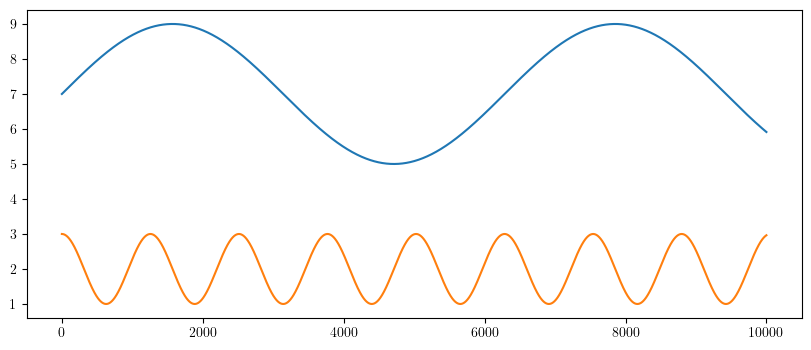

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(10, 4))
ax.plot(sigma_1 + amplitude_1 * np.sin(frequency_1 * np.arange(0, N, 1)))
ax.plot(sigma_2 + amplitude_2 * np.cos(frequency_2 * np.arange(0, N, 1)))
# ax.set_xlim(0, 1000)

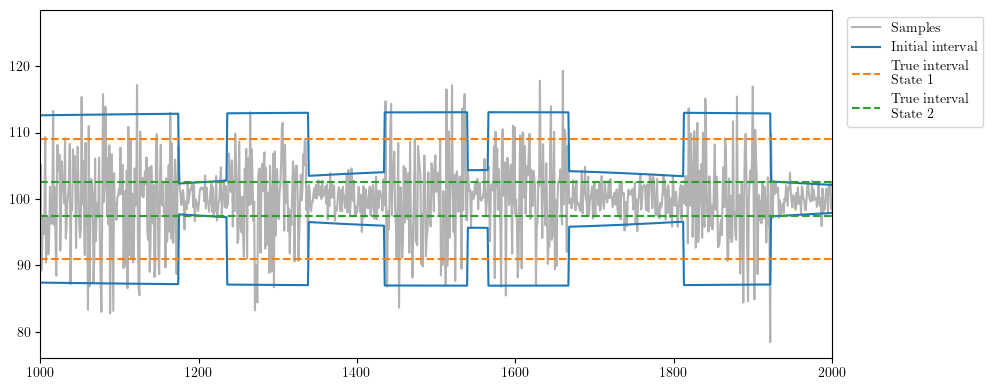

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(10, 4))
ax.plot(np.arange(len(true_values)), true_values, color='black', label='Samples', alpha=0.3)
ax.plot(uppers, label='Initial interval', color='C0')
ax.plot(lowers, color='C0')
ax.plot([stats.norm.ppf(1 - alpha / 2, loc=mu, scale=sigma_1)]*N, '--', color='C1', label='True interval\nState 1')
ax.plot([stats.norm.ppf(alpha / 2, loc=mu, scale=sigma_1)]*N, '--', color='C1')
ax.plot([stats.norm.ppf(1 - alpha / 2, loc=mu, scale=sigma_2)]*N, '--', color='C2', label='True interval\nState 2')
ax.plot([stats.norm.ppf(alpha / 2, loc=mu, scale=sigma_2)]*N, '--', color='C2')
ax.set_xlim(1000, 2000)
ax.legend(frameon=True, loc='upper right', bbox_to_anchor=(1.2, 1))
plt.tight_layout()
plt.show()


In [10]:
# fig, ax = plt.subplots(1, 1, figsize=(10, 4))
# # ax.scatter(range(N), 5 * (np.abs(np.sin(2 * np.pi * np.arange(N) / N)) + 0.1))
# # ax.scatter(range(N), 5 * (np.abs(np.cos(2 * np.pi * np.arange(N) / N)) + 0.1))
# # ax.scatter(range(N), sigmas)
# # ax.scatter(range(N), sigmas_samples)
# ax.scatter(range(N), lengths)
# # ax.set_xlim(0, 10000)
# plt.tight_layout()
# plt.show()

In [11]:
# fig, ax = plt.subplots(1, 1, figsize=(10, 4))
# ax.scatter(lengths, coverages)
# ax.axhline(1-alpha, color='red', linestyle='--')   
# # ax.axvline(true_interval_length, color='green', linestyle='--')
# ax.set_xlabel('Interval length')
# ax.set_ylabel('Coverage')
# ax.set_title('Interval length vs. coverage probability')
# plt.tight_layout()
# plt.show()


In [12]:
df = pd.DataFrame({
    'true_value': true_values,
    # 'random_uniform': random_uniforms,
    'lower': lowers,
    'upper': uppers,
    'theoretical_coverage': coverages,
    'length': lengths,
    'coverage_true_value': coverages_true_value
})

In [13]:
df['length_group'] = pd.qcut(df['length'], 10)

In [14]:
lowers_waci, uppers_waci, list_alphas = WACI(true_values, lowers, uppers, alpha, 0.01, 1, 1000)

  0%|          | 0/9000 [00:00<?, ?it/s]

In [15]:
df['lower_waci'] = np.nan
df['upper_waci'] = np.nan

df.loc[1000:, 'lower_waci'] = lowers_waci
df.loc[1000:, 'upper_waci'] = uppers_waci

df.loc[df.lower_waci == -np.inf, 'lower_waci'] = df.lower.min()
df.loc[df.upper_waci == np.inf, 'upper_waci'] = df.upper.max()

df['length_waci'] = df['upper_waci'] - df['lower_waci']
df['coverage_waci'] = ((df['lower_waci'] <= df['true_value']) & (df['true_value'] <= df['upper_waci'])).astype(int)

In [16]:
lowers_aci, uppers_aci, list_alphas = ACI(true_values, lowers, uppers, alpha, 0.01, 1000)

  0%|          | 0/9000 [00:00<?, ?it/s]

In [17]:
df['lower_aci'] = np.nan
df['upper_aci'] = np.nan

df.loc[1000:, 'lower_aci'] = lowers_aci
df.loc[1000:, 'upper_aci'] = uppers_aci

df.loc[df.lower_aci == -np.inf, 'lower_aci'] = df.lower.min()
df.loc[df.upper_aci == np.inf, 'upper_aci'] = df.upper.max()

df['length_aci'] = df['upper_aci'] - df['lower_aci']
df['coverage_aci'] = ((df['lower_aci'] <= df['true_value']) & (df['true_value'] <= df['upper_aci'])).astype(int)

In [18]:
true_upper_1 = stats.norm.ppf(1 - alpha / 2, loc=mu, scale=sigma_1)
true_lower_1 = stats.norm.ppf(alpha / 2, loc=mu, scale=sigma_1)

true_upper_2 = stats.norm.ppf(1 - alpha / 2, loc=mu, scale=sigma_2)
true_lower_2 = stats.norm.ppf(alpha / 2, loc=mu, scale=sigma_2)

In [19]:
true_uppers = np.zeros(N)
true_uppers[actual_processes == 1] = true_upper_1
true_uppers[actual_processes == 2] = true_upper_2

true_lowers = np.zeros(N)
true_lowers[actual_processes == 1] = true_lower_1
true_lowers[actual_processes == 2] = true_lower_2

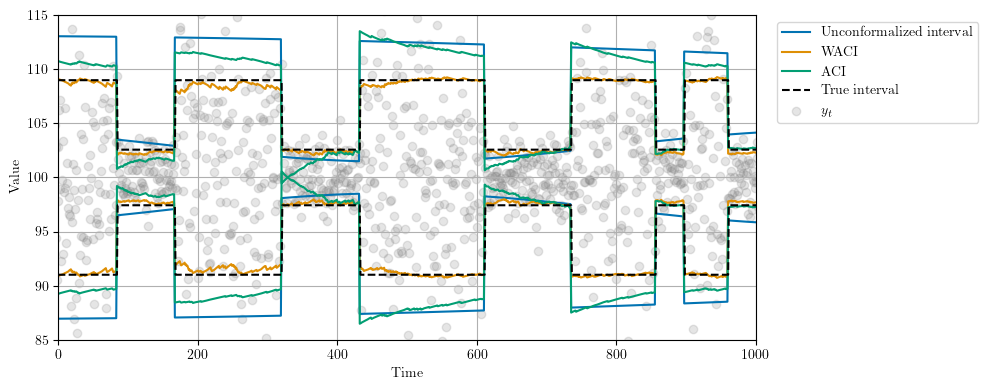

In [20]:
fig, ax = plt.subplots(1, 1, figsize=(10, 4))
ax.plot(df.upper, label='Unconformalized interval', color=colors[0])
ax.plot(df.lower, color=colors[0])
ax.plot(df.upper_waci, label='WACI', color=colors[1])
ax.plot(df.lower_waci, color=colors[1])
ax.plot(df.upper_aci, label='ACI', color=colors[2])
ax.plot(df.lower_aci, color=colors[2])
ax.plot(true_uppers, label='True interval', linestyle='--', color='k')
ax.plot(true_lowers, linestyle='--', color='k')
ax.scatter(df.index, df.true_value, color='grey', alpha=0.2, label='$y_t$')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
ax.grid()
ax.set_xlim(8000, 9000)
ax.set_xlabel('Time')
ax.set_ylabel('Value')
ax.set_xticklabels(range(0, 1001, 200))
ax.set_ylim(85, 115)
plt.tight_layout()
plt.savefig("Images/synthetic_example_2.pdf", bbox_inches='tight', dpi=300)
plt.show()

# 100 simulaciones

In [21]:
dict_results_total = {'initial': {'empirical_coverage': [], 
                                  'average_length': [], 
                                  'median_length': [], 
                                  'winkler_score': [], 
                                  'pearson_correlation': [], 
                                  'ILS_10_coverage': [], 
                                  'mean_deviation_coverage_by_interval_length': []},
                        'aci': {'empirical_coverage': [],
                                'average_length': [],
                                'median_length': [],
                                'winkler_score': [],
                                'pearson_correlation': [],
                                'ILS_10_coverage': [],
                                'mean_deviation_coverage_by_interval_length': []},
                        'waci': {'empirical_coverage': [],
                                'average_length': [],
                                'median_length': [],
                                'winkler_score': [],
                                'pearson_correlation': [],
                                'ILS_10_coverage': [],
                                'mean_deviation_coverage_by_interval_length': []}}

dict_results_process_1 = {'initial': {'empirical_coverage': [], 
                                  'average_length': [], 
                                  'median_length': [], 
                                  'winkler_score': [], 
                                  'pearson_correlation': [], 
                                  'ILS_10_coverage': [], 
                                  'mean_deviation_coverage_by_interval_length': []},
                        'aci': {'empirical_coverage': [],
                                'average_length': [],
                                'median_length': [],
                                'winkler_score': [],
                                'pearson_correlation': [],
                                'ILS_10_coverage': [],
                                'mean_deviation_coverage_by_interval_length': []},
                        'waci': {'empirical_coverage': [],
                                'average_length': [],
                                'median_length': [],
                                'winkler_score': [],
                                'pearson_correlation': [],
                                'ILS_10_coverage': [],
                                'mean_deviation_coverage_by_interval_length': []}}

dict_results_process_2 = {'initial': {'empirical_coverage': [], 
                                  'average_length': [], 
                                  'median_length': [], 
                                  'winkler_score': [], 
                                  'pearson_correlation': [], 
                                  'ILS_10_coverage': [], 
                                  'mean_deviation_coverage_by_interval_length': []},
                        'aci': {'empirical_coverage': [],
                                'average_length': [],
                                'median_length': [],
                                'winkler_score': [],
                                'pearson_correlation': [],
                                'ILS_10_coverage': [],
                                'mean_deviation_coverage_by_interval_length': []},
                        'waci': {'empirical_coverage': [],
                                'average_length': [],
                                'median_length': [],
                                'winkler_score': [],
                                'pearson_correlation': [],
                                'ILS_10_coverage': [],
                                'mean_deviation_coverage_by_interval_length': []}}


mu = 100
alpha=0.2
num_sample = 10
N = 10000
sigma_1 = 7
sigma_2 = 2
prob_change = 0
amplitude_1 = 2
frequency_1 = 0.001
amplitude_2 = 1
frequency_2 = 0.005 
true_interval_length_1 = stats.norm.ppf(1 - alpha / 2, loc=mu, scale=sigma_1) - stats.norm.ppf(alpha / 2, loc=mu, scale=sigma_1)
true_interval_length_2 = stats.norm.ppf(1 - alpha / 2, loc=mu, scale=sigma_2) - stats.norm.ppf(alpha / 2, loc=mu, scale=sigma_2)

for n_experiment in tqdm(range(100)):
    reset_seed(n_experiment)

    coverages = np.zeros(N)
    lengths = np.zeros(N)
    true_values = np.zeros(N)
    coverages_true_value = np.zeros(N)
    uppers = np.zeros(N)
    lowers = np.zeros(N)
    sigmas = np.zeros(N)
    sigmas_samples = np.zeros(N)
    actual_processes = np.zeros(N)

    cont = 0
    actual_process = 1

    sample_std_prev = sigma_1

    for k in range(N):
        actual_processes[k] = actual_process
        if actual_process == 1:
            sigma = sigma_1
        else:
            sigma = sigma_2

        if np.random.uniform() < prob_change and cont > -1:
            if actual_process == 1:
                actual_process = 2
            else:
                actual_process = 1
            prob_change = 0
            cont = 0
        else:
            prob_change += 0.0001
        cont += 1

        sigmas[k] = sigma

        sample = np.random.normal(loc=mu, scale=sigma, size=num_sample)

        if actual_process == 1:
            sample_std = sigma_1 + amplitude_1 * np.sin(frequency_1 * k)
        else:
            sample_std = sigma_2 + amplitude_2 * np.sin(frequency_2 * k)

        sigmas_samples[k] = sample_std

        true_value = np.random.normal(loc=mu, scale=sigma, size=1)
        sample_mean = mu
        
        critical_value = stats.t.ppf(1 - alpha / 2, df=num_sample - 1)
        margin_of_error = critical_value * sample_std * np.sqrt(1 + 1 / num_sample)
        
        lower = sample_mean - margin_of_error
        upper = sample_mean + margin_of_error

        probability_interval = stats.norm.cdf(upper, loc=mu, scale=sigma) - stats.norm.cdf(lower, loc=mu, scale=sigma)

        coverages[k] = probability_interval
        lengths[k] = upper - lower
        coverages_true_value[k] = int((lower <= true_value) and (true_value <= upper))
        true_values[k] = true_value
        uppers[k] = upper
        lowers[k] = lower
    
    df = pd.DataFrame({
        'true_value': true_values,
        'lower': lowers,
        'upper': uppers,
        'theoretical_coverage': coverages,
        'length': lengths,
        'coverage_true_value': coverages_true_value
    })

    
    lowers_waci, uppers_waci, list_alphas = WACI(true_values, lowers, uppers, alpha, 0.01, 1, 1000)

    df['lower_waci'] = np.nan
    df['upper_waci'] = np.nan

    df.loc[1000:, 'lower_waci'] = lowers_waci
    df.loc[1000:, 'upper_waci'] = uppers_waci

    df.loc[df.lower_waci == -np.inf, 'lower_waci'] = df.lower.min()
    df.loc[df.upper_waci == np.inf, 'upper_waci'] = df.upper.max()

    df['length_waci'] = df['upper_waci'] - df['lower_waci']
    df['coverage_waci'] = ((df['lower_waci'] <= df['true_value']) & (df['true_value'] <= df['upper_waci'])).astype(int)

    lowers_aci, uppers_aci, list_alphas = ACI(true_values, lowers, uppers, alpha, 0.01, 1000)

    df['lower_aci'] = np.nan
    df['upper_aci'] = np.nan

    df.loc[1000:, 'lower_aci'] = lowers_aci
    df.loc[1000:, 'upper_aci'] = uppers_aci

    df.loc[df.lower_aci == -np.inf, 'lower_aci'] = df.lower.min()
    df.loc[df.upper_aci == np.inf, 'upper_aci'] = df.upper.max()

    df['length_aci'] = df['upper_aci'] - df['lower_aci']
    df['coverage_aci'] = ((df['lower_aci'] <= df['true_value']) & (df['true_value'] <= df['upper_aci'])).astype(int)

    df['actual_process'] = actual_processes

    df = df.rename(columns={'upper': 'preds_sup_initial', 'lower': 'preds_inf_initial', 'upper_waci': 'preds_sup_waci', 'lower_waci': 'preds_inf_waci', 'upper_aci': 'preds_sup_aci', 'lower_aci': 'preds_inf_aci', 'true_value': 'real'})

    df_aux = df[df.preds_inf_aci.notna()]

    df_actual_process_1 = df_aux[df_aux['actual_process'] == 1]
    df_actual_process_2 = df_aux[df_aux['actual_process'] == 2]

    for model_name in ["initial", "aci", "waci"]:
        dict_results_total[model_name]['empirical_coverage'].append(empirical_coverage(df_aux['real'], df_aux[f'preds_sup_{model_name}'], df_aux[f'preds_inf_{model_name}']))
        dict_results_total[model_name]['average_length'].append(average_length(df_aux[f'preds_sup_{model_name}'], df_aux[f'preds_inf_{model_name}']))
        dict_results_total[model_name]['median_length'].append(median_length(df_aux[f'preds_sup_{model_name}'], df_aux[f'preds_inf_{model_name}']))
        dict_results_total[model_name]['winkler_score'].append(winkler_score(df_aux['real'], df_aux[f'preds_sup_{model_name}'], df_aux[f'preds_inf_{model_name}'], alpha))
        dict_results_total[model_name]['pearson_correlation'].append(pearson_correlation(df_aux['real'], df_aux[f'preds_sup_{model_name}'], df_aux[f'preds_inf_{model_name}']))
        dict_results_total[model_name]['ILS_10_coverage'].append(ILS_coverage(df_aux, model_name, pct_threshold=90, alpha=alpha))
        dict_results_total[model_name]['mean_deviation_coverage_by_interval_length'].append(mean_deviation_coverage_by_interval_length(df_aux, model_name, quantile_step=0.05, alpha=alpha))
    
    for model_name in ["initial", "aci", "waci"]:
        dict_results_process_1[model_name]['empirical_coverage'].append(empirical_coverage(df_actual_process_1['real'], df_actual_process_1[f'preds_sup_{model_name}'], df_actual_process_1[f'preds_inf_{model_name}']))
        dict_results_process_1[model_name]['average_length'].append(average_length(df_actual_process_1[f'preds_sup_{model_name}'], df_actual_process_1[f'preds_inf_{model_name}']))
        dict_results_process_1[model_name]['median_length'].append(median_length(df_actual_process_1[f'preds_sup_{model_name}'], df_actual_process_1[f'preds_inf_{model_name}']))
        dict_results_process_1[model_name]['winkler_score'].append(winkler_score(df_actual_process_1['real'], df_actual_process_1[f'preds_sup_{model_name}'], df_actual_process_1[f'preds_inf_{model_name}'], alpha))
        dict_results_process_1[model_name]['pearson_correlation'].append(pearson_correlation(df_actual_process_1['real'], df_actual_process_1[f'preds_sup_{model_name}'], df_actual_process_1[f'preds_inf_{model_name}']))
        dict_results_process_1[model_name]['ILS_10_coverage'].append(ILS_coverage(df_actual_process_1, model_name, pct_threshold=90, alpha=alpha))
        dict_results_process_1[model_name]['mean_deviation_coverage_by_interval_length'].append(mean_deviation_coverage_by_interval_length(df_actual_process_1, model_name, quantile_step=0.05, alpha=alpha))
    
    for model_name in ["initial", "aci", "waci"]:
        dict_results_process_2[model_name]['empirical_coverage'].append(empirical_coverage(df_actual_process_2['real'], df_actual_process_2[f'preds_sup_{model_name}'], df_actual_process_2[f'preds_inf_{model_name}']))
        dict_results_process_2[model_name]['average_length'].append(average_length(df_actual_process_2[f'preds_sup_{model_name}'], df_actual_process_2[f'preds_inf_{model_name}']))
        dict_results_process_2[model_name]['median_length'].append(median_length(df_actual_process_2[f'preds_sup_{model_name}'], df_actual_process_2[f'preds_inf_{model_name}']))
        dict_results_process_2[model_name]['winkler_score'].append(winkler_score(df_actual_process_2['real'], df_actual_process_2[f'preds_sup_{model_name}'], df_actual_process_2[f'preds_inf_{model_name}'], alpha))
        dict_results_process_2[model_name]['pearson_correlation'].append(pearson_correlation(df_actual_process_2['real'], df_actual_process_2[f'preds_sup_{model_name}'], df_actual_process_2[f'preds_inf_{model_name}']))
        dict_results_process_2[model_name]['ILS_10_coverage'].append(ILS_coverage(df_actual_process_2, model_name, pct_threshold=90, alpha=alpha))
        dict_results_process_2[model_name]['mean_deviation_coverage_by_interval_length'].append(mean_deviation_coverage_by_interval_length(df_actual_process_2, model_name, quantile_step=0.05, alpha=alpha))

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

... (191 outputs left out)

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

In [22]:
df_results_total = pd.DataFrame(columns=['empirical_coverage', 'average_length', 'median_length', 'winkler_score', 'pearson_correlation', 'ILS_10_coverage', 'mean_deviation_coverage_by_interval_length'])
for model_name in ["initial", "aci", "waci"]:
    df_results_total.loc[model_name] = [np.mean(dict_results_total[model_name]['empirical_coverage']),
                            np.mean(dict_results_total[model_name]['average_length']),
                            np.mean(dict_results_total[model_name]['median_length']),
                            np.mean(dict_results_total[model_name]['winkler_score']),
                            np.mean(dict_results_total[model_name]['pearson_correlation']),
                            np.mean(dict_results_total[model_name]['ILS_10_coverage']),
                            np.mean(dict_results_total[model_name]['mean_deviation_coverage_by_interval_length'])
                            ]

df_results_process_1 = pd.DataFrame(columns=['empirical_coverage', 'average_length', 'median_length', 'winkler_score', 'pearson_correlation', 'ILS_10_coverage', 'mean_deviation_coverage_by_interval_length'])
for model_name in ["initial", "aci", "waci"]:
    df_results_process_1.loc[model_name] = [np.mean(dict_results_process_1[model_name]['empirical_coverage']),
                            np.mean(dict_results_process_1[model_name]['average_length']),
                            np.mean(dict_results_process_1[model_name]['median_length']),
                            np.mean(dict_results_process_1[model_name]['winkler_score']),
                            np.mean(dict_results_process_1[model_name]['pearson_correlation']),
                            np.mean(dict_results_process_1[model_name]['ILS_10_coverage']),
                            np.mean(dict_results_process_1[model_name]['mean_deviation_coverage_by_interval_length'])
                            ]

df_results_process_2 = pd.DataFrame(columns=['empirical_coverage', 'average_length', 'median_length', 'winkler_score', 'pearson_correlation', 'ILS_10_coverage', 'mean_deviation_coverage_by_interval_length'])
for model_name in ["initial", "aci", "waci"]:
    df_results_process_2.loc[model_name] = [np.mean(dict_results_process_2[model_name]['empirical_coverage']),
                            np.mean(dict_results_process_2[model_name]['average_length']),
                            np.mean(dict_results_process_2[model_name]['median_length']),
                            np.mean(dict_results_process_2[model_name]['winkler_score']),
                            np.mean(dict_results_process_2[model_name]['pearson_correlation']),
                            np.mean(dict_results_process_2[model_name]['ILS_10_coverage']),
                            np.mean(dict_results_process_2[model_name]['mean_deviation_coverage_by_interval_length'])
                            ]


In [23]:
df_standard_deviation_total = pd.DataFrame(columns=['empirical_coverage', 'average_length', 'median_length', 'winkler_score', 'pearson_correlation', 'ILS_10_coverage', 'mean_deviation_coverage_by_interval_length'])
for model_name in ["initial", "aci", "waci"]:
    df_standard_deviation_total.loc[model_name] = [np.std(dict_results_total[model_name]['empirical_coverage']),
                            np.std(dict_results_total[model_name]['average_length']),
                            np.std(dict_results_total[model_name]['median_length']),
                            np.std(dict_results_total[model_name]['winkler_score']),
                            np.std(dict_results_total[model_name]['pearson_correlation']),
                            np.std(dict_results_total[model_name]['ILS_10_coverage']),
                            np.std(dict_results_total[model_name]['mean_deviation_coverage_by_interval_length'])
                            ]

df_standard_deviation_process_1 = pd.DataFrame(columns=['empirical_coverage', 'average_length', 'median_length', 'winkler_score', 'pearson_correlation', 'ILS_10_coverage', 'mean_deviation_coverage_by_interval_length'])
for model_name in ["initial", "aci", "waci"]:
    df_standard_deviation_process_1.loc[model_name] = [np.std(dict_results_process_1[model_name]['empirical_coverage']),
                            np.std(dict_results_process_1[model_name]['average_length']),
                            np.std(dict_results_process_1[model_name]['median_length']),
                            np.std(dict_results_process_1[model_name]['winkler_score']),
                            np.std(dict_results_process_1[model_name]['pearson_correlation']),
                            np.std(dict_results_process_1[model_name]['ILS_10_coverage']),
                            np.std(dict_results_process_1[model_name]['mean_deviation_coverage_by_interval_length'])
                            ]

df_standard_deviation_process_2 = pd.DataFrame(columns=['empirical_coverage', 'average_length', 'median_length', 'winkler_score', 'pearson_correlation', 'ILS_10_coverage', 'mean_deviation_coverage_by_interval_length'])
for model_name in ["initial", "aci", "waci"]:
    df_standard_deviation_process_2.loc[model_name] = [np.std(dict_results_process_2[model_name]['empirical_coverage']),
                            np.std(dict_results_process_2[model_name]['average_length']),
                            np.std(dict_results_process_2[model_name]['median_length']),
                            np.std(dict_results_process_2[model_name]['winkler_score']),
                            np.std(dict_results_process_2[model_name]['pearson_correlation']),
                            np.std(dict_results_process_2[model_name]['ILS_10_coverage']),
                            np.std(dict_results_process_2[model_name]['mean_deviation_coverage_by_interval_length'])
                            ]

In [24]:
df_results_total

,empirical_coverage,average_length,median_length,winkler_score,pearson_correlation,ILS_10_coverage,mean_deviation_coverage_by_interval_length
initial,82.512111,13.480546,11.399561,16.976770,0.174794,NaN,11.125444
aci,79.931667,12.486196,10.709969,16.487349,0.154897,1.568889,7.891444
waci,80.893778,11.945929,10.713818,16.005768,0.036992,0.883333,3.680444


In [25]:
df_standard_deviation_total

,empirical_coverage,average_length,median_length,winkler_score,pearson_correlation,ILS_10_coverage,mean_deviation_coverage_by_interval_length
initial,0.748416,0.442068,2.997647,0.523598,0.015013,NaN,0.549020
aci,0.026591,0.411842,3.599708,0.521717,0.012764,0.643156,0.422961
waci,0.112692,0.397088,4.748683,0.519009,0.003292,0.650237,0.290262


In [26]:
df_results_process_1

,empirical_coverage,average_length,median_length,winkler_score,pearson_correlation,ILS_10_coverage,mean_deviation_coverage_by_interval_length
initial,85.128257,21.143012,21.876879,26.051022,0.252465,NaN,9.166984
aci,83.243926,19.904206,19.844722,25.478177,0.222317,4.171507,7.252015
waci,81.082879,18.592965,18.587222,24.889473,0.151505,1.748102,4.349637


In [27]:
df_standard_deviation_process_1

,empirical_coverage,average_length,median_length,winkler_score,pearson_correlation,ILS_10_coverage,mean_deviation_coverage_by_interval_length
initial,0.680647,0.234243,0.494962,0.216743,0.014330,NaN,0.516477
aci,0.512631,0.170144,0.300515,0.242651,0.014394,1.526094,0.504126
waci,0.234394,0.232770,0.271682,0.271481,0.014783,1.092439,0.366261


In [28]:
df_results_process_2

,empirical_coverage,average_length,median_length,winkler_score,pearson_correlation,ILS_10_coverage,mean_deviation_coverage_by_interval_length
initial,79.915083,5.875513,5.721889,7.970111,0.338089,NaN,14.274470
aci,76.635606,5.125127,5.057699,7.567644,0.248146,11.686216,9.873302
waci,80.715050,5.349495,5.232297,7.188396,0.097133,1.202252,4.570394


In [29]:
df_standard_deviation_process_2

,empirical_coverage,average_length,median_length,winkler_score,pearson_correlation,ILS_10_coverage,mean_deviation_coverage_by_interval_length
initial,1.187627,0.124990,0.317121,0.098395,0.015587,NaN,0.832762
aci,0.588598,0.091722,0.123198,0.101646,0.018994,2.807457,0.587569
waci,0.127974,0.071910,0.079716,0.086473,0.005279,0.840793,0.358639
